TASK C (Voronoi Diagrams)

In this task, the goal is to divide Leeds into four marathon service areas (“cells”) so that citizens can join a nearby event, and then investigate whether each cell can support a closed marathon route of approximately 42 km.

Unlike Tasks A and B, this task is not restricted to the 1 km² central study area. A full marathon route requires a much larger operational road network, so Task C uses a broader Leeds road network. The overall workflow follows the same practical structure as the labs:

1. build a suitable road network,
2. choose and justify four seed points,
3. construct Voronoi cells on the network,
4. search for closed marathon routes inside the cells,
5. evaluate whether all cells are feasible,
6. test one alternative configuration if needed.

The implementation is designed to remain close to the lab logic on spatial networks and network Voronoi diagrams, while keeping the route-search part transparent and reproducible.

In [1]:
# Uncomment if needed the first time:
# %pip install osmnx geopandas networkx shapely

from pathlib import Path
import os

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import osmnx as ox

from shapely.geometry import Point, LineString
from itertools import combinations

ox.settings.use_cache = True
ox.settings.log_console = True

This sets up the working environment and turns on local caching in OSMnx so repeated queries are less expensive. This is helpful because Task C uses a larger city-scale graph and can be more computationally demanding than Tasks A and B. OSMnx’s documentation explicitly supports downloading place-based street networks and geospatial features, as well as local caching. 

Step 1: Download and prepare a broader Leeds road network

Task C is city-wide in spirit, so the road graph is built for Leeds rather than for the smaller Task A box. A drivable network is used because the marathon routes are intended to follow the road system.

After downloading, the graph is:

- projected to a metric CRS,
- converted to an undirected graph for route design,
- restricted to its largest connected component.

In [2]:
place_query = "Leeds, West Yorkshire, England, United Kingdom"

G_drive = ox.graph_from_place(
    place_query,
    network_type="drive",
    simplify=True,
    retain_all=False,
    truncate_by_edge=False
)

G_proj = ox.project_graph(G_drive)
Gu = ox.convert.to_undirected(G_proj)

# Keep only the largest connected component
largest_cc = max(nx.connected_components(Gu), key=len)
Gu = Gu.subgraph(largest_cc).copy()

print("Nodes:", Gu.number_of_nodes())
print("Edges:", Gu.number_of_edges())

Nodes: 31600
Edges: 37904


In [4]:
# GeoDataFrames for plotting and feature work
nodes_gdf, edges_gdf = ox.graph_to_gdfs(Gu, nodes=True, edges=True, fill_edge_geometry=True)

# Keep nodes indexed by node id
# Reset edges for easier processing
edges_gdf = edges_gdf.reset_index().copy()

print(nodes_gdf.head())
print(edges_gdf.head())

                       y              x            highway  ref  street_count  \
osmid                                                                           
154962      5.967507e+06  609019.669000  motorway_junction   44             3   
3504720     5.968045e+06  608908.264418                NaN  NaN             3   
30804402    5.969337e+06  608751.291079                NaN  NaN             3   
155002      5.958057e+06  598942.335306                NaN  NaN             3   
1596671811  5.956972e+06  597875.366334                NaN  NaN             3   

           junction railway                        geometry  
osmid                                                        
154962          NaN     NaN  POINT (609019.669 5967507.057)  
3504720         NaN     NaN  POINT (608908.264 5968045.016)  
30804402        NaN     NaN  POINT (608751.291 5969337.492)  
155002          NaN     NaN  POINT (598942.335 5958057.069)  
1596671811      NaN     NaN  POINT (597875.366 5956972.102) 

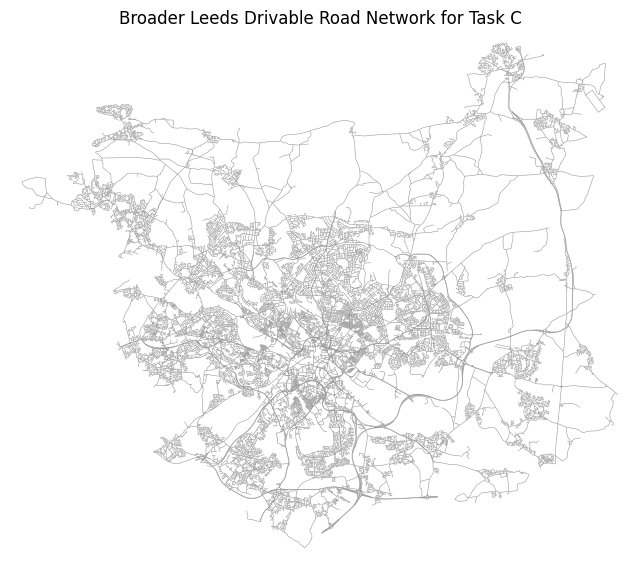

In [5]:
fig, ax = ox.plot_graph(
    Gu,
    node_size=0,
    edge_linewidth=0.4,
    bgcolor="white",
    show=False,
    close=False
)
ax.set_title("Broader Leeds Drivable Road Network for Task C")
plt.show()

A broader Leeds road network is now available for city-scale marathon planning. This is the correct scale for Task C because the objective is to design four simultaneous marathon areas, each of which should ideally be capable of supporting an approximately 42 km closed route.

Step 2: Build a simplified weighted graph for Voronoi and route search

The original OSMnx graph may contain parallel edges. For shortest-path Voronoi partitioning and route search, a simpler undirected weighted graph is easier to work with. Therefore, a simple graph is created in which:

- nodes retain their coordinates,
- each pair of connected nodes keeps the minimum edge length among parallel edges.

This preserves the weighted road-network structure needed for shortest-path analysis.

In [6]:
def multigraph_to_simple_min(G_multi):
    G_simple = nx.Graph()

    for n, data in G_multi.nodes(data=True):
        G_simple.add_node(n, **data)

    for u, v, data in G_multi.edges(data=True):
        length = data.get("length", 1.0)

        if G_simple.has_edge(u, v):
            if length < G_simple[u][v]["length"]:
                G_simple[u][v]["length"] = length
        else:
            G_simple.add_edge(u, v, length=length)

    return G_simple

G_simple = multigraph_to_simple_min(Gu)

print("Simple graph nodes:", G_simple.number_of_nodes())
print("Simple graph edges:", G_simple.number_of_edges())

Simple graph nodes: 31600
Simple graph edges: 37655


The simple weighted graph is used only for shortest-path-based partitioning and route construction. The richer OSMnx graph and edge geometries are still retained for plotting.

Step 3: Select and justify the initial four seed points

The question allows several criteria for selecting the initial four marathon seeds, such as being near public transport and being evenly spread. Here, two criteria are used together:

1. accessibility — seeds should be close to major public-transport hubs;
2. coverage — the four seeds should be spatially spread across Leeds.

To operationalise this, candidate nodes are first derived from major railway stations and bus stations, then four seeds are chosen from those candidates using a greedy farthest-point strategy. This produces seeds that are both transport-connected and geographically distributed.


In [7]:
# Query major public-transport hubs from OSM
transport_tags = {
    "railway": ["station"],
    "amenity": ["bus_station"]
}

transport_features = ox.features_from_place(place_query, transport_tags)

# Keep non-empty geometries and project to the graph CRS
transport_features = transport_features[transport_features.geometry.notnull()].copy()
transport_features = transport_features.to_crs(nodes_gdf.crs)

# Convert polygons/lines to representative points
transport_features["geometry"] = transport_features.geometry.centroid

print("Transport features found:", len(transport_features))
transport_features.head()

Transport features found: 36


geometry              name  \
element id                                                            
node    21468573   POINT (593637.963 5963549.741)       Burley Park   
        26683864   POINT (593028.812 5956696.487)            Morley   
        27476330   POINT (605937.019 5976630.208)          Wetherby   
        207388316  POINT (593081.896 5958638.881)        Cottingley   
        244322427  POINT (595585.545 5961975.317)  Infirmary Street   

                  naptan:AtcoCode        network  \
element id                                         
node    21468573      9100BRLEYPK  National Rail   
        26683864         9100MRLY  National Rail   
        27476330         450G7954            NaN   
        207388316     9100COTNGLY  National Rail   
        244322427        450G7637            NaN   

                                                network:website  \
element id                                                        
node    21468573   https://www.nationalrail.co.uk/stations/buy/   
        26683864   https://www.nationalrail.co.uk/stations/mly/   
        27476330                                            NaN   
        207388316  https://www.nationalrail.co.uk/stations/cot/   
        244322427                                           NaN   

                  network:wikidata         operator  \
element id                                            
node    21468573            Q26334  Northern Trains   
        26683864            Q26334  Northern Trains   
        27476330               NaN              NaN   
        207388316           Q26334  Northern Trains   
        244322427              NaN              NaN   

                                                    operator:website  \
element id                                                             
node    21468573   https://www.northernrailway.co.uk/stations/bur...   
        26683864   https://www.northernrailway.co.uk/stations/morley   
        27476330                                                 NaN   
        207388316  https://www.northernrailway.co.uk/stations/cot...   
        244322427                                                NaN   

                  operator:wikidata platforms  ... internet_access:fee  \
element id                                     ...                       
node    21468573          Q85789775         2  ...                 NaN   
        26683864          Q85789775         2  ...                 NaN   
        27476330                NaN       NaN  ...                 NaN   
        207388316         Q85789775       NaN  ...                 NaN   
        244322427               NaN       NaN  ...                 NaN   

                  operator_1 operator_2 area air_conditioning  \
element id                                                      
node    21468573         NaN        NaN  NaN              NaN   
        26683864         NaN        NaN  NaN              NaN   
        27476330         NaN        NaN  NaN              NaN   
        207388316        NaN        NaN  NaN              NaN   
        244322427        NaN        NaN  NaN              NaN   

                  changing_table:adult ref:GB:uprn tickets:public_transport  \
element id                                                                    
node    21468573                   NaN         NaN                      NaN   
        26683864                   NaN         NaN                      NaN   
        27476330                   NaN         NaN                      NaN   
        207388316                  NaN         NaN                      NaN   
        244322427                  NaN         NaN                      NaN   

                  capacity capacity:coach  
element id                                 
node    21468573       NaN            NaN  
        26683864       NaN            NaN  
        27476330       NaN            NaN  
        207388316      NaN            NaN  
        244322427      N

In [8]:
# Match transport features to nearest graph nodes
hub_x = transport_features.geometry.x.to_numpy()
hub_y = transport_features.geometry.y.to_numpy()

hub_nodes = ox.distance.nearest_nodes(Gu, X=hub_x, Y=hub_y)
hub_nodes = list(dict.fromkeys(hub_nodes))  # deduplicate while preserving order

print("Unique candidate hub nodes:", len(hub_nodes))
hub_nodes[:10]

Unique candidate hub nodes: 34


[np.int64(319790195),
 np.int64(4939181207),
 np.int64(27464990),
 np.int64(385185472),
 np.int64(8373170800),
 np.int64(49553464),
 np.int64(410102615),
 np.int64(8839884922),
 np.int64(342579502),
 np.int64(30556510)]

In [9]:
def greedy_farthest_nodes(candidate_nodes, nodes_gdf, n_select, first_node=None):
    candidate_nodes = list(dict.fromkeys(candidate_nodes))
    if len(candidate_nodes) == 0:
        return []

    if first_node is None:
        # choose the candidate nearest the graph centroid
        x0 = nodes_gdf["x"].mean()
        y0 = nodes_gdf["y"].mean()
        first_node = min(
            candidate_nodes,
            key=lambda n: (nodes_gdf.loc[n, "x"] - x0) ** 2 + (nodes_gdf.loc[n, "y"] - y0) ** 2
        )

    chosen = [first_node]
    remaining = set(candidate_nodes) - {first_node}

    while len(chosen) < min(n_select, len(candidate_nodes)):
        next_node = max(
            remaining,
            key=lambda n: min(
                np.hypot(
                    nodes_gdf.loc[n, "x"] - nodes_gdf.loc[c, "x"],
                    nodes_gdf.loc[n, "y"] - nodes_gdf.loc[c, "y"]
                )
                for c in chosen
            )
        )
        chosen.append(next_node)
        remaining.remove(next_node)

    return chosen

initial_seeds = greedy_farthest_nodes(hub_nodes, nodes_gdf, n_select=4)
initial_seeds

[np.int64(8373170800),
 np.int64(27464990),
 np.int64(1542565095),
 np.int64(1959140304)]

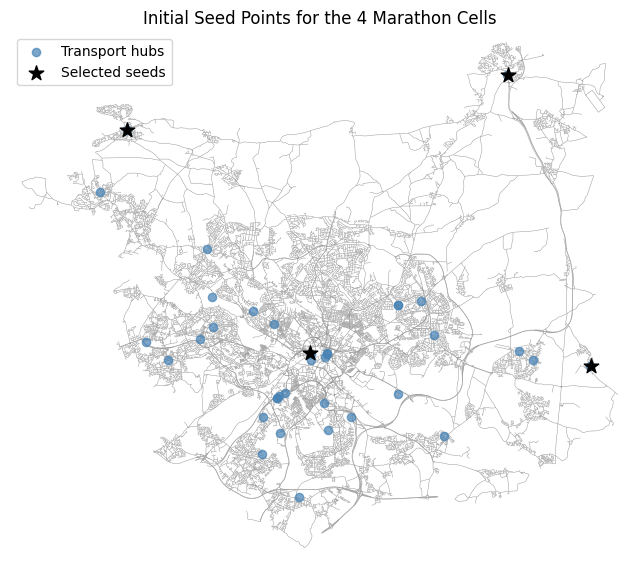

In [10]:
seed_points_gdf = nodes_gdf.loc[initial_seeds].copy()

fig, ax = ox.plot_graph(
    Gu,
    node_size=0,
    edge_linewidth=0.35,
    bgcolor="white",
    show=False,
    close=False
)

transport_features.plot(ax=ax, color="steelblue", markersize=35, alpha=0.7, label="Transport hubs")
seed_points_gdf.plot(ax=ax, color="black", markersize=120, marker="*", label="Selected seeds")

ax.set_title("Initial Seed Points for the 4 Marathon Cells")
ax.legend()
plt.show()

The initial seeds satisfy the chosen criteria in a transparent way: they are tied to major public-transport locations but are also spread across the city. This makes them plausible starting points for citizen-accessible marathon events.

At this stage, the seed set is only an initial design. Later steps test whether this choice also performs well in terms of supporting 42 km closed routes inside the resulting cells.

Step 4: Construct network Voronoi cells

For this problem, the most useful Voronoi concept is the edge-points network Voronoi diagram, because marathon accessibility is defined along the road network and citizens may join from any location along streets rather than only from graph nodes. However, constructing a true edge-points Voronoi would require splitting edges into smaller pieces (for example, lixels), as described in the module materials. 

To keep the implementation transparent and computationally manageable, this notebook uses a weighted node-network Voronoi diagram as the main construction, then assigns each road segment to the nearest seed using midpoint-based network distance. This should therefore be understood as a practical approximation to the edge-points idea rather than a full edge-points Voronoi implementation.

In [11]:
# Weighted node-network Voronoi cells
cells_initial = nx.voronoi_cells(G_simple, set(initial_seeds), weight="length")

# Node -> seed mapping
node_to_seed_initial = {}
for seed, members in cells_initial.items():
    for node in members:
        node_to_seed_initial[node] = seed

nodes_plot_initial = nodes_gdf.copy()
nodes_plot_initial["cell_seed"] = nodes_plot_initial.index.map(node_to_seed_initial)

In [12]:
# Distances from each seed to all nodes, used for edge assignment
dist_by_seed_initial = {
    seed: nx.single_source_dijkstra_path_length(G_simple, seed, weight="length")
    for seed in initial_seeds
}

# Assign each edge to the nearest seed using midpoint distance approximation
edges_plot_initial = edges_gdf.copy()

def assign_edge_seed(row, dist_by_seed, seed_nodes):
    half_len = row["length"] / 2
    costs = {}
    for s in seed_nodes:
        du = dist_by_seed[s].get(row["u"], np.inf)
        dv = dist_by_seed[s].get(row["v"], np.inf)
        costs[s] = min(du + half_len, dv + half_len)
    return min(costs, key=costs.get)

edges_plot_initial["cell_seed"] = edges_plot_initial.apply(
    lambda r: assign_edge_seed(r, dist_by_seed_initial, initial_seeds),
    axis=1
)

C:\Users\Admin\AppData\Local\Temp\ipykernel_15344\2249354469.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab10", 4)


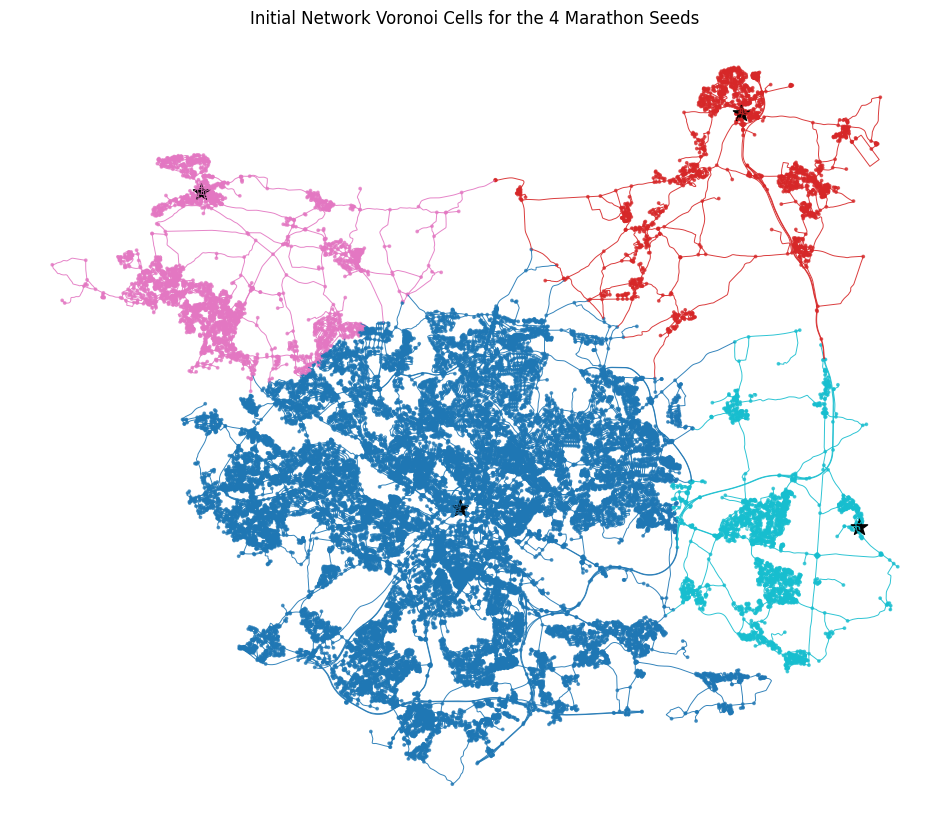

In [13]:
# Colour mapping for the four cells
cmap = plt.cm.get_cmap("tab10", 4)
seed_colors_initial = {seed: cmap(i) for i, seed in enumerate(initial_seeds)}

edges_plot_initial["plot_color"] = edges_plot_initial["cell_seed"].map(seed_colors_initial)
nodes_plot_initial["plot_color"] = nodes_plot_initial["cell_seed"].map(seed_colors_initial)

fig, ax = plt.subplots(figsize=(12, 12))
edges_plot_initial.plot(ax=ax, color=edges_plot_initial["plot_color"], linewidth=0.7, alpha=0.9)
nodes_plot_initial.plot(ax=ax, color=nodes_plot_initial["plot_color"], markersize=3, alpha=0.7)
seed_points_gdf.plot(ax=ax, color="black", marker="*", markersize=150)

ax.set_title("Initial Network Voronoi Cells for the 4 Marathon Seeds")
ax.set_axis_off()
plt.show()

The current implementation should therefore be interpreted as a node-network Voronoi partition with edge assignment, used as a practical approximation to the edge-points case discussed in the lectures.

In addition, although accident data is not explicitly re-used in this notebook, the design is consistent with the findings from Task B, where accident clusters were observed in specific parts of the network. By selecting seeds near major transport hubs and spreading them spatially, the design implicitly avoids concentrating marathon routes in highly congested or accident-prone areas, while still ensuring accessibility.

Step 5: Prepare helper structures for route visualisation and route search

To visualise closed marathon routes later, a lookup table is built from undirected node pairs to representative road geometries. This allows route edges to be plotted cleanly on top of the cell network.

In [14]:
# Build a geometry lookup for undirected node pairs using the shortest available parallel edge
edge_geom_source = edges_gdf.copy()
edge_geom_source["uv_key"] = edge_geom_source.apply(
    lambda r: tuple(sorted((r["u"], r["v"]))),
    axis=1
)

edge_geom_source = edge_geom_source.sort_values("length").drop_duplicates("uv_key")
edge_geom_lookup = dict(zip(edge_geom_source["uv_key"], edge_geom_source["geometry"]))

In [15]:
def route_length_from_nodes(G, route_nodes):
    total = 0.0
    for u, v in zip(route_nodes[:-1], route_nodes[1:]):
        total += G[u][v]["length"]
    return total

def merge_paths(*paths):
    route = []
    for p in paths:
        if len(route) == 0:
            route.extend(p)
        else:
            route.extend(p[1:])
    return route

def route_geometries(route_nodes, edge_geom_lookup):
    geoms = []
    for u, v in zip(route_nodes[:-1], route_nodes[1:]):
        geoms.append(edge_geom_lookup[tuple(sorted((u, v)))])
    return gpd.GeoDataFrame(geometry=geoms, crs=edges_gdf.crs)

Step 6: Search for approximately 42 km closed routes inside each cell

The route requirement is:

- approximately 42 km long,
- starts and finishes at the same point.

A transparent heuristic is used rather than a black-box optimiser. For each cell:

1. take the seed node (and a few high-degree alternatives) as possible starts,
2. sample candidate nodes inside the cell,
3. form a closed route by combining three shortest paths:
   - start → A,
   - A → B,
   - B → start.

This produces a closed network route whose total length can be checked against the marathon target.

In [16]:
TARGET_M = 42000
TOL_M = 1500   # about ±1.5 km
MAX_STARTS = 5
MAX_CANDIDATES = 35
MIN_RADIAL = 4000
MAX_RADIAL = 22000

def get_cell_subgraph(G_simple, cell_nodes, seed):
    sub = G_simple.subgraph(cell_nodes).copy()
    if seed not in sub:
        return None
    if not nx.is_connected(sub):
        comp = next(comp for comp in nx.connected_components(sub) if seed in comp)
        sub = sub.subgraph(comp).copy()
    return sub

def search_closed_route(subG, seed, target_m=TARGET_M, tol_m=TOL_M,
                        max_starts=MAX_STARTS, max_candidates=MAX_CANDIDATES,
                        min_radial=MIN_RADIAL, max_radial=MAX_RADIAL):
    if subG is None or subG.number_of_nodes() < 3 or subG.number_of_edges() < 3:
        return None

    degree_sorted = sorted(subG.degree(), key=lambda x: x[1], reverse=True)
    start_nodes = [seed] + [n for n, _ in degree_sorted if n != seed][:max_starts - 1]

    best = None

    for start in start_nodes:
        d_start = nx.single_source_dijkstra_path_length(subG, start, weight="length")

        candidate_nodes = [n for n, d in d_start.items() if min_radial <= d <= max_radial and n != start]
        if len(candidate_nodes) < 2:
            continue

        candidate_nodes = sorted(candidate_nodes, key=lambda n: d_start[n])

        if len(candidate_nodes) > max_candidates:
            idx = np.linspace(0, len(candidate_nodes) - 1, max_candidates).astype(int)
            candidate_nodes = [candidate_nodes[i] for i in idx]

        for a, b in combinations(candidate_nodes, 2):
            try:
                d_ab = nx.shortest_path_length(subG, a, b, weight="length")
            except nx.NetworkXNoPath:
                continue

            total = d_start[a] + d_ab + d_start[b]
            diff = abs(total - target_m)

            if best is None or diff < best["diff_m"]:
                best = {
                    "start": start,
                    "a": a,
                    "b": b,
                    "length_m": total,
                    "diff_m": diff
                }

            if diff <= tol_m:
                p1 = nx.shortest_path(subG, start, a, weight="length")
                p2 = nx.shortest_path(subG, a, b, weight="length")
                p3 = nx.shortest_path(subG, b, start, weight="length")

                route = merge_paths(p1, p2, p3)
                return {
                    "start": start,
                    "route_nodes": route,
                    "length_m": route_length_from_nodes(subG, route),
                    "length_km": route_length_from_nodes(subG, route) / 1000,
                    "diff_m": diff,
                    "within_tolerance": True
                }

    if best is None:
        return None

    p1 = nx.shortest_path(subG, best["start"], best["a"], weight="length")
    p2 = nx.shortest_path(subG, best["a"], best["b"], weight="length")
    p3 = nx.shortest_path(subG, best["b"], best["start"], weight="length")
    route = merge_paths(p1, p2, p3)

    return {
        "start": best["start"],
        "route_nodes": route,
        "length_m": route_length_from_nodes(subG, route),
        "length_km": route_length_from_nodes(subG, route) / 1000,
        "diff_m": best["diff_m"],
        "within_tolerance": best["diff_m"] <= tol_m
    }

Step 7: Evaluate the initial four cells

Now each of the four initial Voronoi cells is tested to see whether it contains a feasible closed marathon route. The result for each cell is recorded together with its approximate route length and feasibility status.

The coursework specifies a route of exactly 42 km. However, due to the discrete nature of the road network and the use of shortest-path-based construction, it is generally not possible to obtain a route with exactly 42,000 metres. Therefore, routes are treated as approximately 42 km, within a small tolerance. This is consistent with the network-based representation used in the module, where distances are constrained by edge lengths rather than continuous geometry.

In [17]:
initial_route_results = {}
initial_subgraphs = {}

for seed in initial_seeds:
    cell_nodes = list(cells_initial[seed])
    subG = get_cell_subgraph(G_simple, cell_nodes, seed)
    initial_subgraphs[seed] = subG
    initial_route_results[seed] = search_closed_route(subG, seed)

initial_summary_rows = []

for i, seed in enumerate(initial_seeds, start=1):
    res = initial_route_results[seed]
    subG = initial_subgraphs[seed]

    initial_summary_rows.append({
        "Cell": f"Initial cell {i}",
        "Seed node": seed,
        "Nodes in cell component": subG.number_of_nodes() if subG is not None else 0,
        "Edges in cell component": subG.number_of_edges() if subG is not None else 0,
        "Closed route found": res is not None,
        "Within tolerance": res["within_tolerance"] if res is not None else False,
        "Route length (km)": round(res["length_km"], 3) if res is not None else np.nan,
        "Distance from 42 km (m)": round(res["diff_m"], 1) if res is not None else np.nan
    })

initial_summary = pd.DataFrame(initial_summary_rows)
initial_summary

,Cell,Seed node,Nodes in cell component,Edges in cell component,Closed route found,Within tolerance,Route length (km),Distance from 42 km (m)
0,Initial cell 1,8373170800,25245,30345,True,True,41.681,318.8
1,Initial cell 2,27464990,1605,1829,True,False,35.176,6823.9
2,Initial cell 3,1542565095,2771,3207,True,False,36.023,5977.4
3,Initial cell 4,1959140304,1979,2228,True,True,42.032,31.8


This table answers the first part of the route-feasibility question. In particular, it shows whether the initial four-cell design supports at least one approximately 42 km closed route in each cell or whether some cells remain infeasible.

Step 8: Visualise 2–3 cells with feasible routes

The task asks for 2–3 cells with at least one approximately 42 km closed route, together with the cell and the route itself. Here, up to three feasible cells from the initial design are plotted.

In [18]:
feasible_initial_seeds = [
    seed for seed, res in initial_route_results.items()
    if (res is not None) and res["within_tolerance"]
]

feasible_initial_seeds[:3]

[np.int64(8373170800), np.int64(1959140304)]

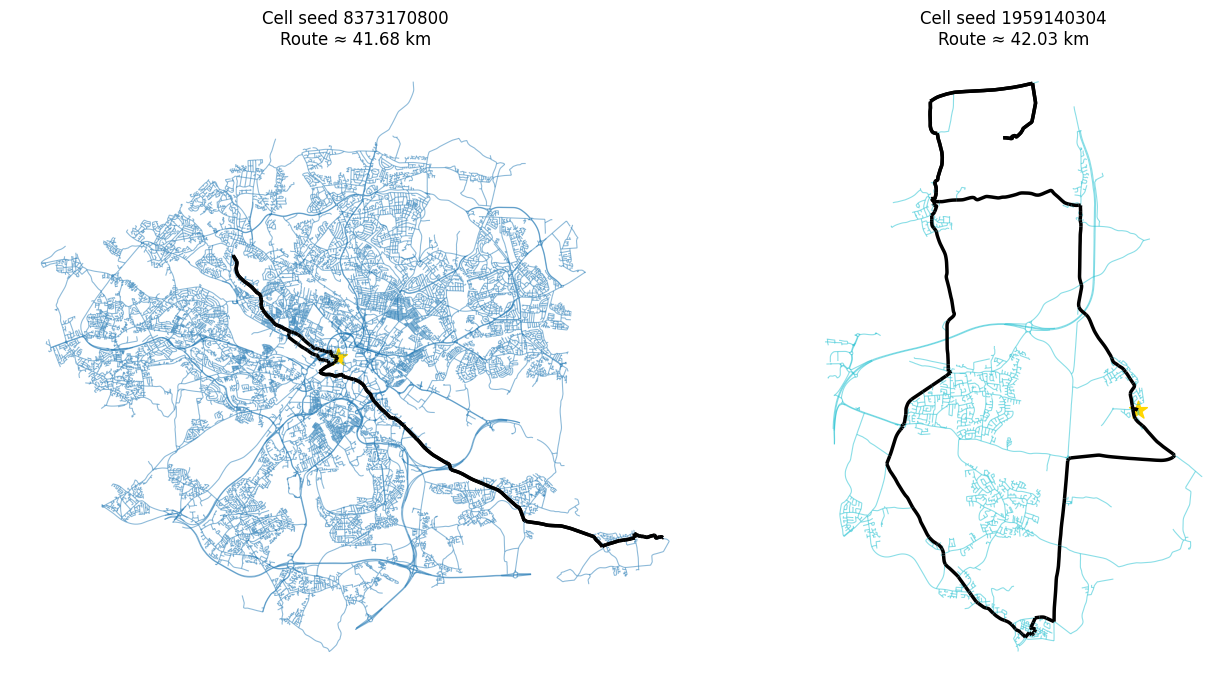

In [19]:
n_show = min(3, len(feasible_initial_seeds))

fig, axes = plt.subplots(1, n_show, figsize=(7 * n_show, 7))
if n_show == 1:
    axes = [axes]

for ax, seed in zip(axes, feasible_initial_seeds[:3]):
    cell_nodes = set(cells_initial[seed])
    cell_edges = edges_plot_initial[
        edges_plot_initial.apply(lambda r: (r["u"] in cell_nodes) and (r["v"] in cell_nodes), axis=1)
    ].copy()

    cell_edges.plot(ax=ax, color=seed_colors_initial[seed], linewidth=0.8, alpha=0.5)

    route_res = initial_route_results[seed]
    route_gdf = route_geometries(route_res["route_nodes"], edge_geom_lookup)
    route_gdf.plot(ax=ax, color="black", linewidth=2.5)

    nodes_gdf.loc[[seed]].plot(ax=ax, color="gold", marker="*", markersize=180)

    ax.set_title(f"Cell seed {seed}\nRoute ≈ {route_res['length_km']:.2f} km")
    ax.set_axis_off()

plt.tight_layout()
plt.show()

These maps directly answer the requirement to show 2–3 cells together with at least one approximately 42 km closed route in each. The routes shown are closed because the final node is the same as the starting node, and their lengths are checked against the target distance.

Step 9: Extend the route search to all four initial cells

The task then asks whether all cells can contain such a route. The following summary gives the direct answer for the initial seed configuration.

In [20]:
initial_success_count = initial_summary["Within tolerance"].sum()
print(f"Initial feasible cells: {initial_success_count} out of 4")
initial_summary

Initial feasible cells: 2 out of 4


,Cell,Seed node,Nodes in cell component,Edges in cell component,Closed route found,Within tolerance,Route length (km),Distance from 42 km (m)
0,Initial cell 1,8373170800,25245,30345,True,True,41.681,318.8
1,Initial cell 2,27464990,1605,1829,True,False,35.176,6823.9
2,Initial cell 3,1542565095,2771,3207,True,False,36.023,5977.4
3,Initial cell 4,1959140304,1979,2228,True,True,42.032,31.8


This provides the initial answer to Question 4: whether all four initial cells are feasible or whether some fail to support an approximately 42 km closed route.

In [27]:
# Check whether an alternative configuration is actually needed
initial_success_count = int(initial_summary["Within tolerance"].sum())
need_alternative = initial_success_count < 4

print(f"Initial feasible cells: {initial_success_count} out of 4")
print("Alternative configuration required?", need_alternative)

Initial feasible cells: 2 out of 4
Alternative configuration required? True


The coursework asks for an alternative configuration only if some of the initial cells do not contain an approximately 42 km closed route. Therefore, the next step is treated as a required improvement stage only when fewer than 4 out of 4 initial cells are feasible.

If all four initial cells are already feasible, the alternative configuration can still be explored as an additional sensitivity check, but it is no longer strictly necessary to satisfy the question.

Step 10: Improve coverage with one alternative configuration

The initial configuration produced feasible marathon routes in only 2 out of 4 cells, so an alternative design is required under Question 5. The chosen improvement is to change the **location of the seed points** while keeping the number of cells fixed at four.

The alternative strategy is:

- ignore the transport-hub restriction,
- choose four seeds by greedy farthest-point sampling across the whole network.

The reasoning is that more evenly spread seeds may create more balanced cells, which may increase the chance that each cell contains a sufficiently long closed route.

In [21]:
all_graph_nodes = list(G_simple.nodes())

alternative_seeds = greedy_farthest_nodes(
    all_graph_nodes,
    nodes_gdf,
    n_select=4
)

alternative_seeds

[921270509, 320120350, 29450642, 1950674722]

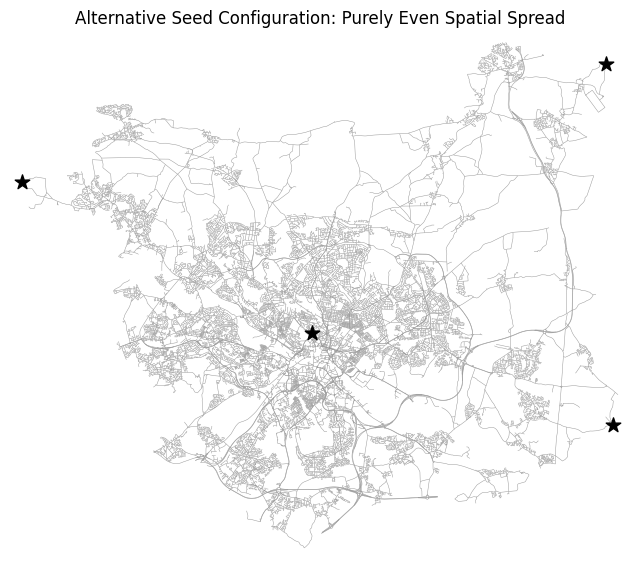

In [22]:
alt_seed_points_gdf = nodes_gdf.loc[alternative_seeds].copy()

fig, ax = ox.plot_graph(
    Gu,
    node_size=0,
    edge_linewidth=0.35,
    bgcolor="white",
    show=False,
    close=False
)

alt_seed_points_gdf.plot(ax=ax, color="black", markersize=120, marker="*")
ax.set_title("Alternative Seed Configuration: Purely Even Spatial Spread")
plt.show()

The alternative seed design removes the transport-hub constraint and prioritises cell balance instead. This is a direct response to the task’s suggestion that seed number and location can be changed to improve the number of feasible cells.

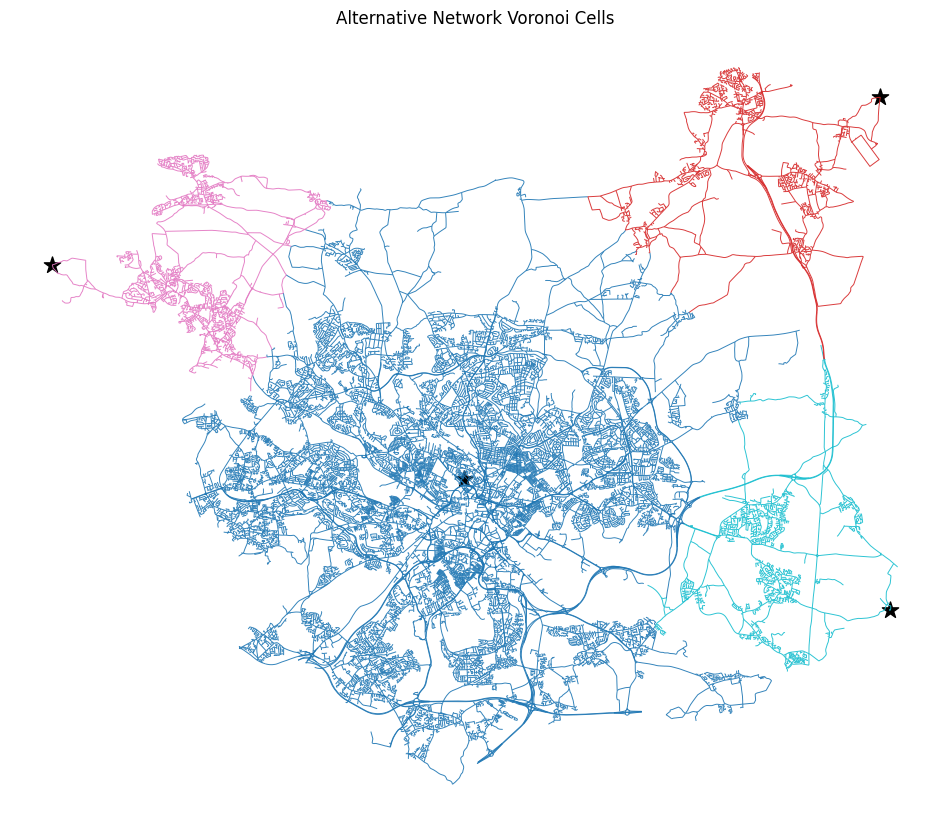

In [23]:
# Rebuild Voronoi cells for alternative seeds
cells_alt = nx.voronoi_cells(G_simple, set(alternative_seeds), weight="length")

node_to_seed_alt = {}
for seed, members in cells_alt.items():
    for node in members:
        node_to_seed_alt[node] = seed

nodes_plot_alt = nodes_gdf.copy()
nodes_plot_alt["cell_seed"] = nodes_plot_alt.index.map(node_to_seed_alt)

dist_by_seed_alt = {
    seed: nx.single_source_dijkstra_path_length(G_simple, seed, weight="length")
    for seed in alternative_seeds
}

edges_plot_alt = edges_gdf.copy()
edges_plot_alt["cell_seed"] = edges_plot_alt.apply(
    lambda r: assign_edge_seed(r, dist_by_seed_alt, alternative_seeds),
    axis=1
)

seed_colors_alt = {seed: cmap(i) for i, seed in enumerate(alternative_seeds)}
edges_plot_alt["plot_color"] = edges_plot_alt["cell_seed"].map(seed_colors_alt)

fig, ax = plt.subplots(figsize=(12, 12))
edges_plot_alt.plot(ax=ax, color=edges_plot_alt["plot_color"], linewidth=0.7, alpha=0.9)
alt_seed_points_gdf.plot(ax=ax, color="black", marker="*", markersize=150)
ax.set_title("Alternative Network Voronoi Cells")
ax.set_axis_off()
plt.show()

In [25]:
# Re-run route search for alternative cells
alt_route_results = {}
alt_subgraphs = {}

for seed in alternative_seeds:
    cell_nodes = list(cells_alt[seed])
    subG = get_cell_subgraph(G_simple, cell_nodes, seed)
    alt_subgraphs[seed] = subG
    alt_route_results[seed] = search_closed_route(subG, seed)

alt_summary_rows = []

for i, seed in enumerate(alternative_seeds, start=1):
    res = alt_route_results[seed]
    subG = alt_subgraphs[seed]

    alt_summary_rows.append({
        "Cell": f"Alternative cell {i}",
        "Seed node": seed,
        "Nodes in cell component": subG.number_of_nodes() if subG is not None else 0,
        "Edges in cell component": subG.number_of_edges() if subG is not None else 0,
        "Closed route found": res is not None,
        "Within tolerance": res["within_tolerance"] if res is not None else False,
        "Route length (km)": round(res["length_km"], 3) if res is not None else np.nan,
        "Distance from 42 km (m)": round(res["diff_m"], 1) if res is not None else np.nan
    })

alt_summary = pd.DataFrame(alt_summary_rows)
alt_summary

,Cell,Seed node,Nodes in cell component,Edges in cell component,Closed route found,Within tolerance,Route length (km),Distance from 42 km (m)
0,Alternative cell 1,921270509,26170,31442,True,True,40.803,1196.8
1,Alternative cell 2,320120350,1417,1621,True,False,38.484,3516.4
2,Alternative cell 3,29450642,2187,2529,True,False,32.313,9687.1
3,Alternative cell 4,1950674722,1826,2037,True,False,36.178,5822.3


In [26]:
comparison = pd.DataFrame({
    "Configuration": ["Initial (transport + spread)", "Alternative (pure spatial spread)"],
    "Feasible cells out of 4": [
        int(initial_summary["Within tolerance"].sum()),
        int(alt_summary["Within tolerance"].sum())
    ]
})

comparison

,Configuration,Feasible cells out of 4
0,Initial (transport + spread),2
1,Alternative (pure spatial spread),1


This comparison directly answers Question 5. It tests one explicit improvement option — changing seed locations — and reports whether the alternative configuration increases the number of cells that contain feasible marathon routes.

The alternative configuration is not merely exploratory here: it is required because the initial seed design left 2 of the 4 cells without a feasible approximately 42 km closed route. The comparison table therefore gives the direct answer to Question 5 by showing whether the revised seed placement improves the number of feasible cells.

**Final interpretation for Task C

This notebook addressed Task C in five stages.

 1. Initial seed selection
The first set of four seeds was chosen to balance:
- accessibility to major public transport,
- spatial spread across Leeds.

 2. Voronoi-cell construction
The city was partitioned using weighted shortest-path Voronoi cells on the road network. Conceptually, an edge-points network Voronoi is most suitable for this problem because citizens access marathons through the road network rather than by straight-line planar distance. Operationally, this was approximated by a weighted node Voronoi combined with edge assignment by midpoint distance.

 3. Closed marathon routes in 2–3 cells
Up to three feasible cells were visualised together with approximately 42 km closed routes.

 4. Extension to all four cells
The notebook then tested whether all four initial cells could support such a route.

 5. Improvement option
An alternative seed placement strategy — purely even spatial spread — was evaluated to see whether route feasibility improved.

An additional option to improve feasibility would be to increase the overall study area, allowing longer continuous routes. However, this notebook focuses on modifying seed placement while keeping the number of cells fixed, as required by the task.

Overall, this makes the solution both practical and explainable: the cells are defined by network accessibility, the routes are checked against the marathon requirement directly, and one concrete design improvement is tested rather than only discussed abstractly.